In [2]:
import pandas as pd
import seaborn as sns

# Cargar datos
ad_data = pd.read_csv('../datasets/advertising.xls')

# Vistazo rápido
print(ad_data.head())

   Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  \
0                     68.95   35     61833.90                256.09   
1                     80.23   31     68441.85                193.77   
2                     69.47   26     59785.94                236.50   
3                     74.15   29     54806.18                245.89   
4                     68.37   35     73889.99                225.58   

                           Ad Topic Line            City  Male     Country  \
0     Cloned 5thgeneration orchestration     Wrightburgh     0     Tunisia   
1     Monitored national standardization       West Jodi     1       Nauru   
2       Organic bottom-line service-desk        Davidton     0  San Marino   
3  Triple-buffered reciprocal time-frame  West Terrifurt     1       Italy   
4          Robust logistical utilization    South Manuel     0     Iceland   

             Timestamp  Clicked on Ad  
0  2016-03-27 00:53:11              0  
1  2016-04-04 01:39:02  

In [3]:
print(ad_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB
None


In [4]:
from sklearn.model_selection import train_test_split

# Eliminar texto
X = ad_data[['Daily Time Spent on Site', 'Age', 'Area Income','Daily Internet Usage', 'Male']]
y = ad_data['Clicked on Ad']

# Split (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

Matriz de correlación calculada.


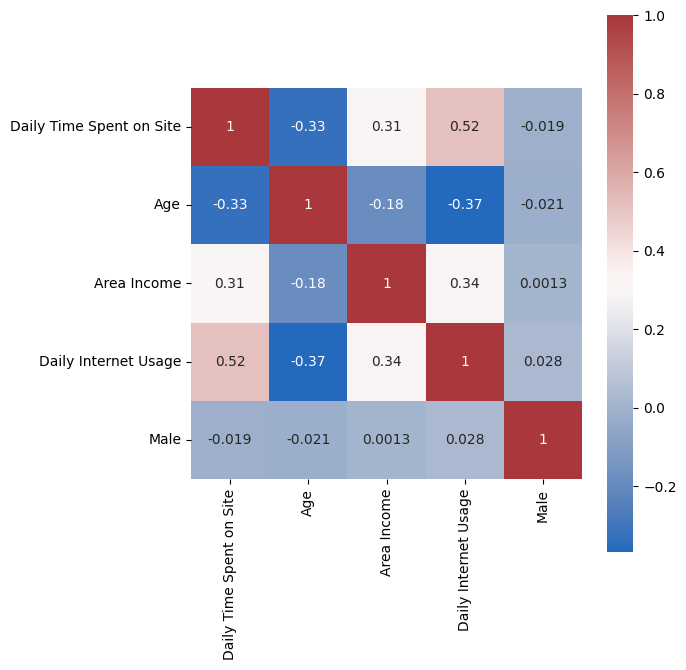

In [5]:
import matplotlib.pyplot as plt

# --- 2. Calcular la correlación ---
# Usamos el método .corr() en el DataFrame de precios
correlation = X.corr()

print("Matriz de correlación calculada.")

# --- 3. Generar el Heatmap ---
# Configuramos el tamaño de la figura para que sea grande y legible
plt.figure(figsize=(7, 7))

# Creamos el heatmap con seaborn
sns.heatmap(
    correlation,        # La matriz de correlación
    vmax=1,             # El valor máximo de la barra de color (1 es correlación perfecta)
    square=True,        # Asegura que cada celda sea un cuadrado
    annot=True,         # Muestra los números (coeficientes de correlación) en cada celda
    cmap='vlag'         # El mapa de color (rojo-blanco-azul) que usa la guía
)

# Ajustamos el layout para que no se corten las etiquetas
plt.tight_layout()

# Mostramos el gráfico
plt.show()

In [6]:
from sklearn.tree import DecisionTreeClassifier

# Crear y Entrenar
dtree = DecisionTreeClassifier(max_depth=7, min_samples_leaf=50) # max_depth=7, min_samples_leaf=150
dtree.fit(X_train,y_train)

print("Árbol entrenado exitosamente.")

Árbol entrenado exitosamente.


In [7]:
from sklearn.metrics import classification_report, confusion_matrix

# Predecir
predictions = dtree.predict(X_test)

# Evaluar
print(classification_report(y_test,predictions))
print(confusion_matrix(y_test,predictions))

              precision    recall  f1-score   support

           0       0.97      0.89      0.92       157
           1       0.88      0.97      0.92       143

    accuracy                           0.92       300
   macro avg       0.92      0.93      0.92       300
weighted avg       0.93      0.92      0.92       300

[[139  18]
 [  5 138]]


In [9]:
from sklearn.metrics import roc_curve, roc_auc_score

auc = roc_auc_score(y_test, predictions)

print(f"AUC: {auc:.4f}")

AUC: 0.9252


              precision    recall  f1-score   support

           0       0.97      0.89      0.92       157
           1       0.88      0.97      0.92       143

    accuracy                           0.92       300
   macro avg       0.92      0.93      0.92       300
weighted avg       0.93      0.92      0.92       300



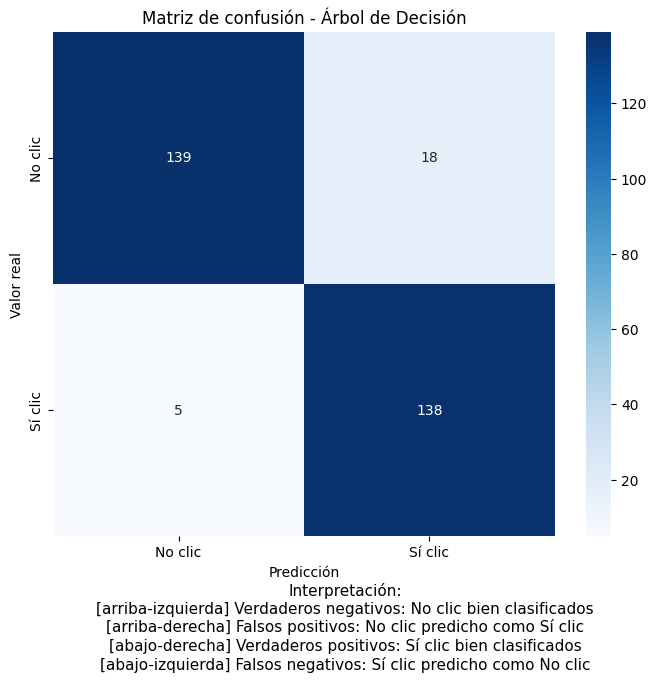

In [91]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predecir
predictions = dtree.predict(X_test)

# Matriz de confusión
cm = confusion_matrix(y_test, predictions)

# Mostrar reporte de clasificación
print(classification_report(y_test, predictions))

# Visualizar matriz de confusión
plt.figure(figsize=(7,6))
ax = sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['No clic', 'Sí clic'],
    yticklabels=['No clic', 'Sí clic']
)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de confusión - Árbol de Decisión')

plt.tight_layout()

# Interpretación debajo del gráfico
plt.figtext(
    0.5, -0.12,
    "Interpretación:\n"
    "[arriba-izquierda] Verdaderos negativos: No clic bien clasificados\n"
    "[arriba-derecha] Falsos positivos: No clic predicho como Sí clic\n"
    "[abajo-derecha] Verdaderos positivos: Sí clic bien clasificados\n"
    "[abajo-izquierda] Falsos negativos: Sí clic predicho como No clic",
    wrap=True, ha='center', fontsize=11
)

plt.show()

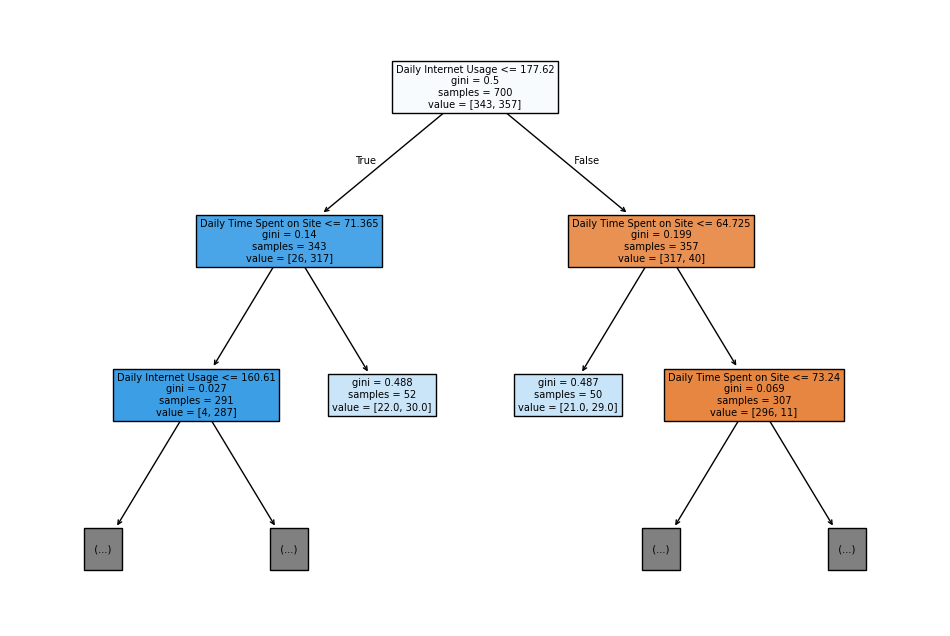

In [92]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
plot_tree(dtree, feature_names=X.columns, filled=True, max_depth=2)
plt.show()

In [77]:
!pip install dtreeviz


[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Datos del Usuario:
Daily Time Spent on Site       39.96
Age                            35.00
Area Income                 53898.89
Daily Internet Usage          138.52
Male                            1.00
Name: 716, dtype: float64
¿Hizo clic realmente?: 1


c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\dtreeviz\models\shadow_decision_tree.py:335: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\dtreeviz\trees.py:1231: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect

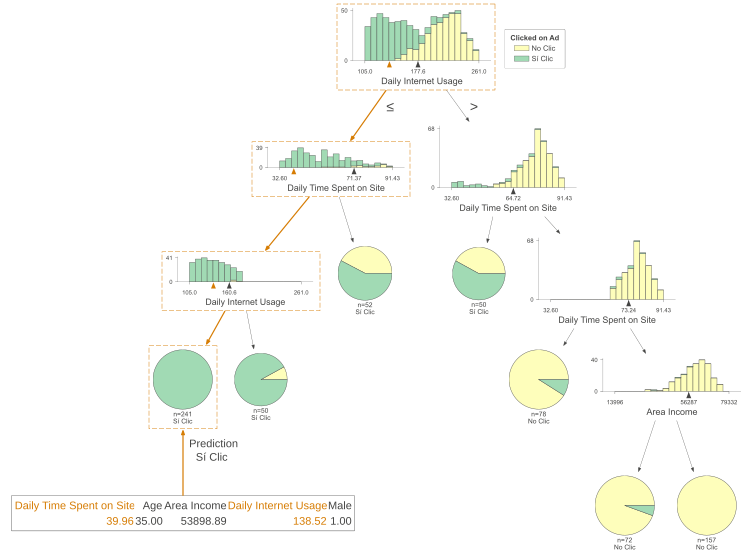

In [93]:
import dtreeviz

# 1. Elegimos un usuario cualquiera del set de prueba (por ejemplo, el primero)
import random
# Elegimos un usuario al azar del test
idx = random.choice(X_test.index)
usuario_ejemplo = X_test.loc[idx] 
clase_real = y_test.loc[idx]

print(f"Datos del Usuario:\n{usuario_ejemplo}")
print(f"¿Hizo clic realmente?: {clase_real}")

# 2. Generar la visualización del camino
viz = dtreeviz.model(dtree, 
                    X_train, 
                    y_train,
                    target_name="Clicked on Ad",
                    feature_names=X.columns.tolist(),
                    class_names=["No Clic", "Sí Clic"])

# 3. Mostrar el camino de ESTE usuario
# (Esto generará un gráfico SVG interactivo donde se ve la ruta resaltada)
v = viz.view(x=usuario_ejemplo)
v

In [79]:
def explicar_decision(modelo, columnas, datos_usuario):
    """
    Simula el recorrido paso a paso de un usuario por el árbol.
    """
    # Obtener el nodo actual (empezamos en la raíz, nodo 0)
    node_indicator = modelo.decision_path([datos_usuario])
    leaf_id = modelo.apply([datos_usuario])
    feature = modelo.tree_.feature
    threshold = modelo.tree_.threshold
    
    node_index = node_indicator.indices[node_indicator.indptr[0]:
                                        node_indicator.indptr[1]]

    print("🔍 INICIO DEL RECORRIDO DEL ÁRBOL")
    print("-" * 40)
    
    for node_id in node_index:
        # Si es un nodo hoja (final)
        if leaf_id[0] == node_id:
            prediccion = modelo.predict([datos_usuario])[0]
            resultado = "HARÁ CLIC" if prediccion == 1 else "NO HARÁ CLIC"
            print(f"\n🏁 LLEGADA A HOJA (Nodo {node_id}):")
            print(f"   ¡Decisión Final! El modelo predice: {resultado}")
            break
            
        # Si es un nodo de decisión
        else:
            # Qué variable se evalúa aquí
            feature_name = columnas[feature[node_id]]
            # Cuál es el valor de corte
            corte = threshold[node_id]
            # Cuál es el valor del usuario
            valor_usuario = datos_usuario[feature[node_id]]
            
            print(f"📍 NODO {node_id}: Pregunta ¿{feature_name} <= {corte:.2f}?")
            print(f"   -> El usuario tiene: {valor_usuario:.2f}")
            
            if valor_usuario <= corte:
                print("   ✅ SÍ (Vamos a la rama IZQUIERDA)")
            else:
                print("   ❌ NO (Vamos a la rama DERECHA)")
            print("   " + "|" )
            print("   " + "v" )

# --- PROBAR CON UN USUARIO ---
# Elegimos un usuario al azar del test
usuario_x = X_test.loc[idx]

print(f"Analizando Usuario ID: {idx}\n")
explicar_decision(dtree, X.columns, usuario_x)

Analizando Usuario ID: 379

🔍 INICIO DEL RECORRIDO DEL ÁRBOL
----------------------------------------
📍 NODO 0: Pregunta ¿Daily Internet Usage <= 177.62?
   -> El usuario tiene: 248.19
   ❌ NO (Vamos a la rama DERECHA)
   |
   v
📍 NODO 24: Pregunta ¿Daily Time Spent on Site <= 54.11?
   -> El usuario tiene: 81.11
   ❌ NO (Vamos a la rama DERECHA)
   |
   v
📍 NODO 26: Pregunta ¿Area Income <= 25803.88?
   -> El usuario tiene: 56216.57
   ❌ NO (Vamos a la rama DERECHA)
   |
   v
📍 NODO 28: Pregunta ¿Age <= 52.00?
   -> El usuario tiene: 39.00
   ✅ SÍ (Vamos a la rama IZQUIERDA)
   |
   v
📍 NODO 29: Pregunta ¿Area Income <= 36836.39?
   -> El usuario tiene: 56216.57
   ❌ NO (Vamos a la rama DERECHA)
   |
   v
📍 NODO 33: Pregunta ¿Area Income <= 78320.25?
   -> El usuario tiene: 56216.57
   ✅ SÍ (Vamos a la rama IZQUIERDA)
   |
   v
📍 NODO 34: Pregunta ¿Age <= 30.50?
   -> El usuario tiene: 39.00
   ❌ NO (Vamos a la rama DERECHA)
   |
   v

🏁 LLEGADA A HOJA (Nodo 60):
   ¡Decisión Final! E

c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
C:\Users\magal\AppData\Local\Temp\ipykernel_12272\126495983.py:33: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
